# Sales Data Analysis

This notebook explores the cleaned sales dataset to identify patterns,
trends, and insights related to products, categories, revenue,
orders, discounts, and customer transactions.

The analysis is performed using Python, Pandas, NumPy, Matplotlib, and Seaborn.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df=pd.read_csv("../Data/cleaned_sales_data.csv")

## 1. Dataset Overview

The cleaned dataset is first inspected to understand its structure,
dimensions, columns, data types, and the availability of values.

In [2]:
df.shape

(102, 18)

In [3]:
df.head()

,ID,Customer_Name,Order_ID,Order_Date,Product,Category,Quantity,Price,Payment_Method,Status,Total,Quantity_clean,Price_clean,Expected_Total,Difference,Adjustment_ratio,Discount_Rate,Order_Date_clean
0,100,Customer_100,ORD-41285,11/22/2024,blender,home,3,38,Cash on Delivery,Shipped,114.00,3.0,38.00,114.00,0.0,1.0,0.0,2024-11-22
1,101,Customer_101,ORD-35783,7/5/2025,smartphone,electronics,2,abd,PayPal,Processing,NaN,2.0,NaN,NaN,NaN,NaN,NaN,2025-07-05
2,102,Customer_102,ORD-84355,12/23/2024,tennis racket,sports,1,389.05,PayPal,Delivered,389.05,1.0,389.05,389.05,0.0,1.0,0.0,2024-12-23
3,103,Customer_103,ORD-57811,3/19/2025,science,books,5,233.92,PayPal,Processing,1169.60,5.0,233.92,1169.60,0.0,1.0,0.0,2025-03-19
4,104,Customer_104,ORD-93614,10/20/2025,biography,books,1,552.51,Cash on Delivery,Processing,552.51,1.0,552.51,552.51,0.0,1.0,0.0,2025-10-20


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 102 entries, 0 to 101
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ID                102 non-null    int64  
 1    Customer_Name    102 non-null    str    
 2   Order_ID          102 non-null    str    
 3   Order_Date        102 non-null    str    
 4   Product           102 non-null    str    
 5    Category         102 non-null    str    
 6   Quantity          97 non-null     str    
 7   Price             97 non-null     str    
 8   Payment_Method    102 non-null    str    
 9   Status            102 non-null    str    
 10  Total             91 non-null     float64
 11  Quantity_clean    97 non-null     float64
 12  Price_clean       95 non-null     float64
 13  Expected_Total    91 non-null     float64
 14  Difference        90 non-null     float64
 15  Adjustment_ratio  88 non-null     float64
 16  Discount_Rate     88 non-null     float64
 17  Order_Da

## 2. Key Business Metrics

The first step of the analysis is to calculate key business metrics
that provide an overall view of the e-commerce dataset.

The main metrics considered are:

- Total number of orders
- Number of unique customers
- Number of unique products
- Total quantity sold
- Total sales value
- Average order value

These metrics provide a high-level understanding of the size and
performance of the dataset before performing deeper analysis.

In [5]:
df["Order_ID"].nunique()

100

In [6]:
df[" Customer_Name"].nunique()

100

In [7]:
df["Product"].nunique()

20

In [8]:
df["Quantity_clean"].sum()

np.float64(299.0)

In [9]:
df["Total"].sum()

np.float64(159151.44999999995)

In [10]:
df["Total"].mean()

np.float64(1748.9170329670324)

## 3. Sales Performance by Category

### KPI Summary

The dataset contains 100 unique orders from 100 unique customers,
covering 20 different products.

A total of 299 units are recorded across the transactions.

The total recorded sales value is approximately ₹159,151.45,
with an average order value of approximately ₹1,748.92.

The dataset contains 102 rows but only 100 unique orders, indicating
that some records represent duplicate order entries. Therefore,
order-level analysis should use `Order_ID` carefully to avoid
double-counting.

The recorded sales value should not yet be interpreted as realized
revenue because the dataset contains cancelled and returned orders.

In [11]:
df.groupby(" Category")["Total"].sum()

 Category
books          39320.910
clothing       32491.010
electronics    43012.122
home           25029.710
sports         19297.698
Name: Total, dtype: float64

### Sales by Category

Sales were grouped by product category to identify which categories
contribute the most to the recorded sales value.

Electronics generated the highest recorded sales value at approximately
₹43,012.12, followed by Books at ₹39,320.91 and Clothing at ₹32,491.01.

Home generated approximately ₹25,029.71, while Sports had the lowest
recorded sales value at approximately ₹19,297.70.

This shows that Electronics is currently the strongest category by
recorded sales value, while Sports contributes the least.

In [12]:
df.groupby(" Category")["Quantity_clean"].sum()

 Category
books          79.0
clothing       66.0
electronics    51.0
home           59.0
sports         44.0
Name: Quantity_clean, dtype: float64

#### Units Sold by Category

The total quantity sold was also analyzed to understand whether
sales value is driven by the number of units sold.

Books recorded the highest quantity sold with 79 units, followed by
Clothing with 66 units and Home with 59 units.

Interestingly, Electronics generated the highest sales value despite
selling only 51 units. This suggests that the higher sales value of
Electronics may be influenced by higher-priced products rather than
higher sales volume.

In [13]:
df.groupby(" Category")["Price_clean"].mean()

 Category
books          563.451364
clothing       528.437333
electronics    892.747391
home           475.939444
sports         493.720000
Name: Price_clean, dtype: float64

In [14]:
df.groupby("Product")["Total"].sum().sort_values(ascending=False)

Product
blender          28075.380
shoes            16987.080
comics           14454.344
lamp             14306.440
biography         9577.390
t-shirt           8230.260
science           8005.710
basketball        7837.770
fiction           7283.466
yoga mat          5694.500
football          5268.638
smartphone        5104.380
microwave         4873.510
jacket            4299.520
jeans             4112.910
vacuum            4062.120
tennis racket     3674.330
smartwatch        3424.120
laptop            2993.560
headphones         886.022
Name: Total, dtype: float64

In [15]:
df.groupby("Product")["Price_clean"].mean().sort_values(ascending=False)

Product
blender          1603.811250
football          789.995000
comics            743.046667
t-shirt           662.560000
fiction           644.938000
lamp              627.228571
shoes             573.820000
smartphone        560.987500
smartwatch        538.343333
basketball        537.814286
vacuum            533.322500
biography         488.476000
laptop            428.547500
jeans             421.410000
tennis racket     400.035000
yoga mat          384.092000
science           378.430000
jacket            358.293333
microwave         352.905000
headphones        306.476667
Name: Price_clean, dtype: float64

In [16]:
df.groupby(" Category").agg({'Quantity_clean':'sum','Price_clean':'mean'})

,Quantity_clean,Price_clean
Category,,
books,79.0,563.451364
clothing,66.0,528.437333
electronics,51.0,892.747391
home,59.0,475.939444
sports,44.0,493.720000


### Category Sales Analysis

Electronics generated the highest recorded sales value among all
categories, followed by Books and Clothing. Although Books recorded
the highest number of units sold, Electronics achieved higher sales
with fewer units.

This is mainly associated with Electronics having the highest average
unit price among the categories. Therefore, the category's strong
sales value appears to be influenced by higher-priced products rather
than sales volume alone.

However, the average unit price and total quantity cannot be directly
multiplied to reproduce the recorded sales value because the dataset
contains discounts and missing values.

## 4. Order Status Analysis

In [17]:
df["Status"].value_counts()

Status
Returned      27
Processing    26
Shipped       23
Cancelled     15
Delivered     11
Name: count, dtype: int64

In [18]:
df.groupby("Status")["Order_ID"].nunique().sort_values(ascending=False)

Status
Returned      27
Processing    25
Shipped       22
Cancelled     15
Delivered     11
Name: Order_ID, dtype: int64

In [19]:
df.groupby("Status")["Order_ID"].nunique()/df.groupby("Status")["Order_ID"].nunique().sum()*100

Status
Cancelled     15.0
Delivered     11.0
Processing    25.0
Returned      27.0
Shipped       22.0
Name: Order_ID, dtype: float64

The distribution of unique orders was analyzed using `Order_ID` to
avoid counting duplicate records as separate orders.

Returned orders represent 27% of unique orders, followed by Processing
at 25%, Shipped at 22%, Cancelled at 15%, and Delivered at 11%.

The relatively high proportion of returned and cancelled orders is
notable and may indicate potential issues with order fulfillment or
customer satisfaction. However, further context would be required
before drawing a definitive conclusion, particularly because many
orders are still in Processing or Shipped status.

## 5. Payment Method Analysis


In [20]:
df["Payment_Method"].value_counts()

Payment_Method
Cash on Delivery    33
PayPal              24
Credit Card         23
Bank Transfer       22
Name: count, dtype: int64

In [21]:
df.groupby("Payment_Method")["Total"].sum().sort_values(ascending=False)

Payment_Method
Cash on Delivery    63841.644
Bank Transfer       41612.830
PayPal              27306.124
Credit Card         26390.852
Name: Total, dtype: float64

In [22]:
df.groupby("Payment_Method")["Total"].mean().sort_values(ascending=False)

Payment_Method
Bank Transfer       2190.148947
Cash on Delivery    2128.054800
PayPal              1365.306200
Credit Card         1199.584182
Name: Total, dtype: float64

In [23]:
pd.crosstab(df["Status"],df["Payment_Method"])

Payment_Method,Bank Transfer,Cash on Delivery,Credit Card,PayPal
Status,,,,
Cancelled,3,7,2,3
Delivered,3,1,3,4
Processing,8,7,4,7
Returned,6,9,8,4
Shipped,2,9,6,6


In [24]:
(pd.crosstab(df["Status"],df["Payment_Method"])/df["Payment_Method"].value_counts()*100).round(2)

Payment_Method,Bank Transfer,Cash on Delivery,Credit Card,PayPal
Status,,,,
Cancelled,13.64,21.21,8.70,12.50
Delivered,13.64,3.03,13.04,16.67
Processing,36.36,21.21,17.39,29.17
Returned,27.27,27.27,34.78,16.67
Shipped,9.09,27.27,26.09,25.00


Cash on Delivery was the most frequently used payment method, with
33 orders, and it also generated the highest recorded sales value.

However, Bank Transfer had the highest average order value at
approximately ₹2,190.15, despite having fewer transactions.

A cross-tabulation of payment methods and order statuses showed that
Cash on Delivery had the highest number of returned orders in absolute
terms. However, when return rates were compared relative to the number
of orders for each payment method, Credit Card had the highest return
rate at approximately 34.78%.

This demonstrates why proportions and rates can provide more meaningful
comparisons than raw counts when groups have different numbers of
transactions.

In [25]:
df["Order_Date_clean"].dtype

<StringDtype(storage='python', na_value=nan)>

In [26]:
df["Order_Date_clean"]=pd.to_datetime(df["Order_Date_clean"])

In [27]:
df["Order_Date_clean"].dtype

dtype('<M8[us]')

## 6. Monthly Sales Analysis and Anomaly Investigation

In [28]:
df.groupby(df["Order_Date_clean"].dt.to_period('M'))["Total"].sum().sort_values(ascending=False)

Order_Date_clean
2025-02    39769.292
2025-10    21099.410
2025-06    17876.430
2025-07    14818.504
2025-01    11373.326
2024-11    11323.350
2025-05    10959.030
2025-09     7471.680
2024-12     7027.810
2025-03     5675.860
2025-08     5104.558
2023-05     1721.980
2023-01     1532.040
2025-11     1383.380
2025-04     1200.280
Freq: M, Name: Total, dtype: float64

In [29]:
df1=df[(df["Order_Date_clean"].dt.year == 2025) & (df["Order_Date_clean"].dt.month == 2)]

In [30]:
df1.shape

(14, 18)

In [31]:
df1[["Order_Date_clean", "Product", " Category", "Quantity_clean", "Price_clean", "Total"]]

,Order_Date_clean,Product,Category,Quantity_clean,Price_clean,Total
6,2025-02-02,blender,home,NaN,978.63,NaN
17,2025-02-12,blender,electronics,2.0,10000.00,20000.000
25,2025-02-09,comics,books,4.0,765.69,3062.760
35,2025-02-09,smartwatch,electronics,4.0,446.19,1784.760
37,2025-02-23,vacuum,home,3.0,100.00,300.000
39,2025-02-09,smartphone,electronics,2.0,681.38,1362.760
40,2025-02-26,fiction,books,4.0,588.98,2355.920
41,2025-02-13,fiction,books,3.0,546.04,1638.120
54,2025-02-21,blender,home,5.0,789.64,3948.200
64,2025-02-09,tennis racket,sports,NaN,587.64,NaN


In [32]:
df1["Order_ID"].nunique()

13

In [33]:
df1["Quantity_clean"].sum()

np.float64(38.0)

In [34]:
df1.groupby("Product")["Total"].sum().sort_values(ascending=False)

Product
blender          23948.200
lamp              4722.700
fiction           3994.040
comics            3062.760
smartwatch        1784.760
smartphone        1362.760
jeans              404.760
vacuum             300.000
headphones         189.312
tennis racket        0.000
Name: Total, dtype: float64

In [35]:
df1.groupby("Product")["Price_clean"].mean().sort_values(ascending=False)

Product
blender          3922.756667
lamp              944.540000
comics            765.690000
smartphone        681.380000
tennis racket     587.640000
fiction           567.510000
smartwatch        446.190000
headphones        111.360000
jeans             101.190000
vacuum            100.000000
Name: Price_clean, dtype: float64

In [36]:
df1[df1["Product"]=="blender"][
    ["Quantity_clean","Price_clean","Total"]
]

,Quantity_clean,Price_clean,Total
6,NaN,978.63,NaN
17,2.0,10000.00,20000.0
54,5.0,789.64,3948.2


In [37]:
df[df["Product"] == "blender"][
    ["Quantity_clean","Price_clean","Total"]
]

,Quantity_clean,Price_clean,Total
0,3.0,38.00,114.00
6,NaN,978.63,NaN
17,2.0,10000.00,20000.00
27,5.0,336.02,1680.10
54,5.0,789.64,3948.20
62,2.0,155.76,311.52
97,1.0,160.16,160.16
99,5.0,372.28,1861.40


In [38]:
blender=df[df["Product"]=="blender"]

In [39]:
Q1=blender["Price_clean"].quantile(0.25)
Q1

np.float64(159.06)

In [40]:
Q3=blender["Price_clean"].quantile(0.75)
Q3

np.float64(836.8875)

In [41]:
IQR=Q3 - Q1
IQR

np.float64(677.8275000000001)

In [42]:
Lower_boundary=Q1 - 1.5*(IQR)
Lower_boundary

np.float64(-857.6812500000001)

In [43]:
Upper_boundary=Q3 + 1.5*(IQR)
Upper_boundary

np.float64(1853.6287500000003)

In [44]:
outlier_transaction = df1[
    (df1["Product"] == "blender") &
    (df1["Price_clean"] == 10000)
]
outlier_transaction[["Order_ID", "Product", "Quantity_clean", "Price_clean", "Total"]]

,Order_ID,Product,Quantity_clean,Price_clean,Total
17,ORD-72751,blender,2.0,10000.0,20000.0


In [45]:
feb_sales = df1["Total"].sum()
feb_sales_without_outlier = feb_sales - outlier_transaction["Total"].sum()
outlier_contribution = (
    outlier_transaction["Total"].sum() / feb_sales
) * 100
outlier_contribution

np.float64(50.29005796733822)

In [46]:
monthly_sales=df.groupby(df["Order_Date_clean"].dt.to_period('M'))["Total"].sum().sort_values(ascending=False)
adjusted_monthly_sales = monthly_sales.copy()
adjusted_monthly_sales.loc[pd.Period("2025-02")] = feb_sales_without_outlier
adjusted_monthly_sales.sort_values(ascending=False)

Order_Date_clean
2025-10    21099.410
2025-02    19769.292
2025-06    17876.430
2025-07    14818.504
2025-01    11373.326
2024-11    11323.350
2025-05    10959.030
2025-09     7471.680
2024-12     7027.810
2025-03     5675.860
2025-08     5104.558
2023-05     1721.980
2023-01     1532.040
2025-11     1383.380
2025-04     1200.280
Freq: M, Name: Total, dtype: float64

In [47]:
october_df=df[(df["Order_Date_clean"].dt.year == 2025) & (df["Order_Date_clean"].dt.month == 10)]
october_df.shape

(12, 18)

In [48]:
october_df[["Order_Date_clean", "Product", " Category", "Quantity_clean", "Price_clean", "Total", "Expected_Total", "Adjustment_ratio"]]

,Order_Date_clean,Product,Category,Quantity_clean,Price_clean,Total,Expected_Total,Adjustment_ratio
4,2025-10-20,biography,books,1.0,552.51,552.51,552.51,1.0
8,2025-10-23,science,books,1.0,600.29,600.29,600.29,1.0
11,2025-10-22,comics,books,2.0,865.77,1731.54,1731.54,1.0
16,2025-10-30,microwave,home,4.0,NaN,NaN,NaN,NaN
21,2025-10-11,basketball,sports,4.0,523.01,2092.04,2092.04,1.0
23,2025-10-06,vacuum,electronics,3.0,615.91,1847.73,1847.73,1.0
34,2025-10-04,t-shirt,clothing,5.0,591.53,2957.65,2957.65,1.0
42,2025-10-30,shoes,clothing,5.0,645.26,2258.41,3226.30,0.7
70,2025-10-03,jeans,clothing,5.0,741.63,3708.15,3708.15,1.0
73,2025-10-11,lamp,home,5.0,351.89,1759.45,1759.45,1.0


In [49]:
october_df["Total"].sum()

np.float64(21099.41)

In [50]:
october_df["Total"].isna().sum()

np.int64(1)

In [51]:
october_df.shape[0]

12



February 2025 recorded the highest monthly sales value in the original
dataset, at approximately ₹39,769.29.

Further investigation revealed that a single blender transaction
valued at ₹20,000 contributed approximately 50.29% of February's
recorded sales. The transaction was identified as a statistical
outlier using the IQR method. However, being an outlier does not
necessarily mean that the transaction is incorrect.

In a hypothetical sensitivity analysis excluding this transaction,
February's recorded sales decreased to approximately ₹19,769.29.
Under this scenario, October 2025 became the month with the highest
recorded sales value, at approximately ₹21,099.41.

October also contains a transaction with a missing total, meaning
its complete sales value cannot be determined from the available data.

Therefore, February 2025 has the highest recorded sales in the
original dataset, while October 2025 ranks highest under the
hypothetical scenario excluding the unusual February transaction.
Neither result alone establishes which month genuinely performed
best without further verification of the underlying transactions.

# 7. Customer Sales Analysis

## Objective
Analyze customer-level sales to identify high-value customers and investigate whether recorded sales are concentrated among a small number of customers.


In [52]:
df.groupby(" Customer_Name")["Total"].sum().sort_values(ascending=False).head(1)

 Customer_Name
Customer_117    20000.0
Name: Total, dtype: float64

In [53]:
df.loc[
    df[" Customer_Name"] == "Customer_117",
    ["Order_Date_clean", "Product", "Total", " Category",
     "Quantity_clean", "Price_clean", "Status"]
]

,Order_Date_clean,Product,Total,Category,Quantity_clean,Price_clean,Status
17,2025-02-12,blender,20000.0,electronics,2.0,10000.0,Processing


In [54]:
df[df[" Customer_Name"] == "Customer_117"]

,ID,Customer_Name,Order_ID,Order_Date,Product,Category,Quantity,Price,Payment_Method,Status,Total,Quantity_clean,Price_clean,Expected_Total,Difference,Adjustment_ratio,Discount_Rate,Order_Date_clean
17,117,Customer_117,ORD-72751,2/12/2025,blender,electronics,-2,10000,Cash on Delivery,Processing,20000.0,2.0,10000.0,20000.0,0.0,1.0,0.0,2025-02-12


In [55]:
df.groupby(" Customer_Name")["Total"].sum().sort_values(ascending=False).head(5)

 Customer_Name
Customer_117    20000.00
Customer_142     5484.71
Customer_194     4722.70
Customer_149     4481.90
Customer_144     4245.35
Name: Total, dtype: float64

In [56]:
df[df[" Customer_Name"] == "Customer_142"]

,ID,Customer_Name,Order_ID,Order_Date,Product,Category,Quantity,Price,Payment_Method,Status,Total,Quantity_clean,Price_clean,Expected_Total,Difference,Adjustment_ratio,Discount_Rate,Order_Date_clean
42,142,Customer_142,ORD-69018,10/30/2025,shoes,clothing,5,645.26,Credit Card,Shipped,2258.41,5.0,645.26,3226.3,967.89,0.7,30.0,2025-10-30
101,142,Customer_142,ORD-69018,10/30/2025,shoes,clothing,5,645.26,Credit Card,Shipped,3226.30,5.0,645.26,3226.3,0.00,1.0,0.0,2025-10-30


In [57]:
df[df["Order_ID"] == "ORD-69018"]

,ID,Customer_Name,Order_ID,Order_Date,Product,Category,Quantity,Price,Payment_Method,Status,Total,Quantity_clean,Price_clean,Expected_Total,Difference,Adjustment_ratio,Discount_Rate,Order_Date_clean
42,142,Customer_142,ORD-69018,10/30/2025,shoes,clothing,5,645.26,Credit Card,Shipped,2258.41,5.0,645.26,3226.3,967.89,0.7,30.0,2025-10-30
101,142,Customer_142,ORD-69018,10/30/2025,shoes,clothing,5,645.26,Credit Card,Shipped,3226.30,5.0,645.26,3226.3,0.00,1.0,0.0,2025-10-30


In [66]:
df[df.duplicated(subset=["Order_ID"], keep=False)]

,ID,Customer_Name,Order_ID,Order_Date,Product,Category,Quantity,Price,Payment_Method,Status,Total,Quantity_clean,Price_clean,Expected_Total,Difference,Adjustment_ratio,Discount_Rate,Order_Date_clean
42,142,Customer_142,ORD-69018,10/30/2025,shoes,clothing,5,645.26,Credit Card,Shipped,2258.410,5.0,645.26,3226.30,967.890,0.7,30.0,2025-10-30
75,175,Customer_175,ORD-56651,2/24/2025,headphones,electronics,1,111.36,Credit Card,Processing,111.360,1.0,111.36,111.36,0.000,1.0,0.0,2025-02-24
100,175,Customer_175,ORD-56651,2/24/2025,headphones,electronics,1,111.36,Credit Card,Processing,77.952,1.0,111.36,111.36,33.408,0.7,30.0,2025-02-24
101,142,Customer_142,ORD-69018,10/30/2025,shoes,clothing,5,645.26,Credit Card,Shipped,3226.300,5.0,645.26,3226.30,0.000,1.0,0.0,2025-10-30


In [67]:
df_unique_orders=df.drop_duplicates(subset=["Order_ID"], keep="first")

In [68]:
df_unique_orders.groupby(" Customer_Name")["Total"].sum().sort_values(ascending=False).head(5)

 Customer_Name
Customer_117    20000.00
Customer_194     4722.70
Customer_149     4481.90
Customer_144     4245.35
Customer_143     4133.85
Name: Total, dtype: float64

In [72]:
df[df["Discount_Rate"] == 30]

,ID,Customer_Name,Order_ID,Order_Date,Product,Category,Quantity,Price,Payment_Method,Status,Total,Quantity_clean,Price_clean,Expected_Total,Difference,Adjustment_ratio,Discount_Rate,Order_Date_clean
15,115,Customer_115,ORD-72778,1/10/2025,fiction,books,2,796.84,Cash on Delivery,Returned,1115.576,2.0,796.84,1593.68,478.104,0.7,30.0,2025-01-10
42,142,Customer_142,ORD-69018,10/30/2025,shoes,clothing,5,645.26,Credit Card,Shipped,2258.410,5.0,645.26,3226.30,967.890,0.7,30.0,2025-10-30
51,151,Customer_151,ORD-56552,7/1/2025,comics,books,2,457.16,PayPal,Processing,640.024,2.0,457.16,914.32,274.296,0.7,30.0,2025-07-01
85,185,Customer_185,ORD-57123,8/14/2025,football,sports,2,730.92,Cash on Delivery,Cancelled,1023.288,2.0,730.92,1461.84,438.552,0.7,30.0,2025-08-14
100,175,Customer_175,ORD-56651,2/24/2025,headphones,electronics,1,111.36,Credit Card,Processing,77.952,1.0,111.36,111.36,33.408,0.7,30.0,2025-02-24


In [73]:
problematic_orders = ["ORD-69018", "ORD-56651"]

df_customer_analysis = df_unique_orders[
    ~df_unique_orders["Order_ID"].isin(problematic_orders)
]

In [74]:
df_customer_analysis.groupby(" Customer_Name")["Total"].sum().sort_values(ascending=False).head(5)

 Customer_Name
Customer_117    20000.00
Customer_194     4722.70
Customer_149     4481.90
Customer_144     4245.35
Customer_143     4133.85
Name: Total, dtype: float64

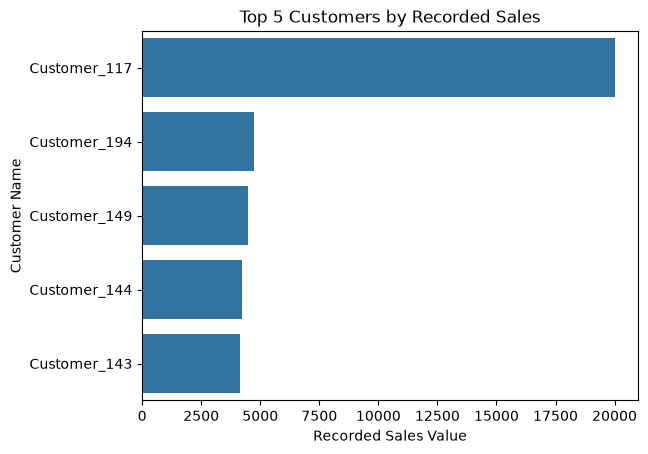

In [75]:
top_customers = (
    df_customer_analysis
    .groupby(" Customer_Name")["Total"]
    .sum()
    .sort_values(ascending=False)
    .head(5)
    .reset_index()
)
sns.barplot(
    data=top_customers,
    x="Total",
    y=" Customer_Name"
)

plt.xlabel("Recorded Sales Value")
plt.ylabel("Customer Name")
plt.title("Top 5 Customers by Recorded Sales")
plt.show()

## Key Findings

- **Highest-Value Customer:** The initial ranking identified `Customer_117` as the highest-value customer, with recorded sales of ₹20,000.

- **Unusual Transaction:** Further investigation revealed that this amount came from a single transaction involving two blenders at a recorded unit price of ₹10,000.

- **Statistical Outlier:** The ₹10,000 unit price was identified as a statistical outlier using the Interquartile Range (IQR) method.

- **Impact on Monthly Sales:** This transaction contributed approximately **50.29% of February 2025's recorded sales value**.

- **Conflicting Duplicate Records:** Two Order IDs, `ORD-69018` and `ORD-56651`, contained duplicate records with conflicting recorded totals.

## Data Quality Considerations

The available data does not establish whether the unusual blender price is erroneous. Therefore, the transaction has been retained in the primary dataset rather than removed solely because it was identified as a statistical outlier.

The two conflicting Order IDs were temporarily excluded from the customer-ranking sensitivity analysis because the correct recorded totals could not be established from the available information.

## Conclusion

This analysis demonstrates how individual anomalies and inconsistent records can influence customer rankings and recorded sales figures.

Further analysis is required to determine whether recorded sales are concentrated among a small number of customers. The next step is to calculate the **percentage of total recorded sales contributed by the top five customers**.

In [79]:
(df_customer_analysis.groupby(" Customer_Name")["Total"].sum().sort_values(ascending=False).head(5).sum()/df_customer_analysis.groupby(" Customer_Name")["Total"].sum().sum())*100

np.float64(24.48816121677515)

In [83]:
(df_customer_analysis.groupby(" Customer_Name")["Total"].sum().sort_values(ascending=False).head(20).sum()/df_customer_analysis.groupby(" Customer_Name")["Total"].sum().sum())*100

np.float64(54.598113280866315)

In [87]:
customer_sales = (
    df_customer_analysis
    .groupby(" Customer_Name")["Total"]
    .sum()
    .sort_values(ascending=False)
)
total_sale=df_customer_analysis.groupby(" Customer_Name")["Total"].sum().sum()
cumulative_percentage=customer_sales.cumsum()/total_sale*100
customer_pareto = pd.DataFrame({
    "Customer_Name": customer_sales.index,
    "Total_Sales": customer_sales.values,
    "Cumulative_Percentage": cumulative_percentage.values
})

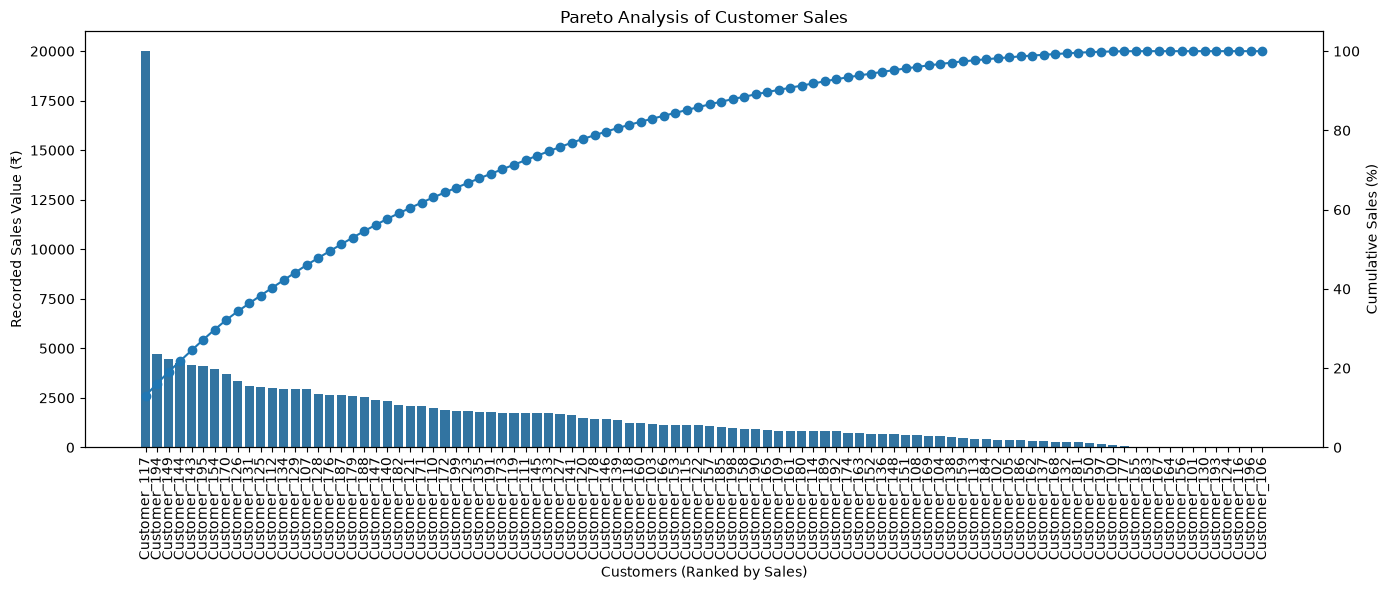

In [88]:
fig, ax1 = plt.subplots(figsize=(14, 6))
sns.barplot(
    data=customer_pareto,
    x="Customer_Name",
    y="Total_Sales",
    ax=ax1
)

ax1.set_xlabel("Customers (Ranked by Sales)")
ax1.set_ylabel("Recorded Sales Value (₹)")
ax1.set_title("Pareto Analysis of Customer Sales")
ax1.tick_params(axis="x", rotation=90)
ax2 = ax1.twinx()
ax2.plot(
    range(len(customer_pareto)),
    customer_pareto["Cumulative_Percentage"],
    marker="o",
    linestyle="-"
)
ax2.set_ylabel("Cumulative Sales (%)")
ax2.set_ylim(0, 105)
plt.tight_layout()
plt.show()

In [89]:
(df_customer_analysis.groupby(" Customer_Name")["Total"].sum().sort_values(ascending=False).head(1).sum()/df_customer_analysis.groupby(" Customer_Name")["Total"].sum().sum())*100

np.float64(13.031232188748959)

In [97]:
temporary_data=df_customer_analysis[df_customer_analysis[" Customer_Name"]!="Customer_117"]
top_5=temporary_data.groupby(" Customer_Name")["Total"].sum().sort_values(ascending=False).head(5)
top5_percent=(top_5.sum()/temporary_data.groupby(" Customer_Name")["Total"].sum().sum()*100).round(2)
top_10=temporary_data.groupby(" Customer_Name")["Total"].sum().sort_values(ascending=False).head(10)
top10_percent=(top_10.sum()/temporary_data.groupby(" Customer_Name")["Total"].sum().sum()*100).round(2)

### Sensitivity Analysis: Excluding Customer_117

To investigate the influence of Customer_117's unusual transaction
on customer sales concentration, a sensitivity analysis was performed
using a temporary dataset.

Customer_117 was excluded, along with the two unresolved duplicate
Order IDs, `ORD-69018` and `ORD-56651`, to avoid counting conflicting
transaction records in this comparison.

After these exclusions:

- The top five customers accounted for approximately **16.24%**
  of recorded sales.
- The top ten customers accounted for approximately **29.08%**
  of recorded sales.

Compared with the initial analysis, where the top five customers
accounted for 24.49% and the top ten accounted for 36.32%, the
percentages were lower in the sensitivity analysis.

However, the two analyses use different datasets, so this difference
reflects both the exclusion of Customer_117 and the exclusion of the
two unresolved orders.

### Conclusion

The sensitivity analysis demonstrates that the customer concentration
results are influenced by unusual transactions and unresolved records.

The findings suggest that recorded sales are distributed across
multiple customers rather than being dominated entirely by a small
group. However, the results should be interpreted cautiously because
the dataset contains missing values and unresolved transactions.

The original cleaned dataset remains unchanged; the exclusions were
applied only to the temporary analysis dataset.

## 8. Product Category Performance and Order Outcomes

### Objective

Analyze order outcomes across different product categories to identify
categories with higher return and cancellation rates and understand
how recorded sales value varies across different order statuses.


In [100]:
df_customer_analysis.shape

(98, 18)

In [101]:
df_customer_analysis["Order_ID"].nunique()

98

In [125]:
df_order_status=pd.crosstab(df_customer_analysis[" Category"],df_customer_analysis["Status"])

In [126]:
(df_order_status["Returned"]/df_customer_analysis[" Category"].value_counts()*100).round(2)

 Category
books          43.48
clothing       20.00
electronics    18.18
home           25.00
sports         27.78
dtype: float64

In [127]:
(df_order_status["Cancelled"]/df_customer_analysis[" Category"].value_counts()*100).round(2)

 Category
books          13.04
clothing       13.33
electronics    22.73
home           10.00
sports         16.67
dtype: float64

In [128]:
df_customer_analysis.groupby([" Category","Status"])["Total"].sum()

 Category    Status    
books        Cancelled      4764.880
             Processing     4613.334
             Returned      21673.856
             Shipped        8268.840
clothing     Cancelled      7481.050
             Delivered      3894.780
             Processing     9432.750
             Returned        855.470
             Shipped        5342.250
electronics  Cancelled      6761.730
             Delivered      4024.820
             Processing    22247.600
             Returned       5190.260
             Shipped        4598.400
home         Cancelled      4108.360
             Delivered       300.000
             Processing     1451.430
             Returned       8228.330
             Shipped       10941.590
sports       Cancelled      3389.468
             Delivered      5087.100
             Processing     7113.710
             Returned       2865.720
             Shipped         841.700
Name: Total, dtype: float64

In [129]:
temporary_data.groupby([" Category","Status"])["Total"].sum()

 Category    Status    
books        Cancelled      4764.880
             Processing     4613.334
             Returned      21673.856
             Shipped        8268.840
clothing     Cancelled      7481.050
             Delivered      3894.780
             Processing     9432.750
             Returned        855.470
             Shipped        5342.250
electronics  Cancelled      6761.730
             Delivered      4024.820
             Processing     2247.600
             Returned       5190.260
             Shipped        4598.400
home         Cancelled      4108.360
             Delivered       300.000
             Processing     1451.430
             Returned       8228.330
             Shipped       10941.590
sports       Cancelled      3389.468
             Delivered      5087.100
             Processing     7113.710
             Returned       2865.720
             Shipped         841.700
Name: Total, dtype: float64

### 1. Order Distribution by Category

The analysis was performed using `df_customer_analysis`, which contains
98 unique orders after excluding the two unresolved duplicate Order IDs.

The order distribution was:

| Category | Total Orders |
|---|---:|
| Books | 23 |
| Clothing | 15 |
| Electronics | 22 |
| Home | 20 |
| Sports | 18 |

Books had the highest number of orders, while clothing had the lowest.

### 2. Return Rate by Category

Return rates were calculated using the following formula:

Return Rate = (Returned Orders / Total Orders) * 100

| Category | Return Rate |
|---|---:|
| Books | 43.48% |
| Clothing | 20.00% |
| Electronics | 18.18% |
| Home | 25.00% |
| Sports | 27.78% |

**Key Findings:**

- Books recorded the highest return rate at 43.48%.
- Electronics recorded the lowest return rate at 18.18%.
- Sports had a return rate of 27.78%.
- Clothing and home recorded return rates of 20% and 25%, respectively.

The high return rate for books may indicate customer dissatisfaction
or other product-related issues. However, the available dataset does
not provide the actual reasons for returns.

### 3. Cancellation Rate by Category

Cancellation rates were calculated using the following formula:

Cancellation Rate = (Cancelled Orders / Total Orders) * 100

| Category | Cancellation Rate |
|---|---:|
| Books | 13.04% |
| Clothing | 13.33% |
| Electronics | 22.73% |
| Home | 10.00% |
| Sports | 16.67% |

**Key Findings:**

- Electronics recorded the highest cancellation rate at 22.73%.
- Home recorded the lowest cancellation rate at 10%.
- Books and clothing had relatively similar cancellation rates.

Interestingly, electronics had the lowest return rate but the highest
cancellation rate among the five categories.

This suggests that different product categories may experience
different order-related challenges. However, the reasons behind
these differences cannot be established using the available data.

### 4. Recorded Sales Value by Category and Order Status

Recorded sales values were grouped by product category and order status.

**Key Observations:**

- Books had approximately ₹21,673.86 in recorded sales associated
  with returned orders, compared with ₹4,764.88 associated with
  cancelled orders.
- The recorded sales value associated with returned books was
  approximately 4.55 times the value associated with cancelled books.
- Electronics had approximately ₹22,247.60 in recorded sales
  associated with processing orders.
- Home had approximately ₹10,941.59 in recorded sales associated
  with shipped orders.

These observations show why both order percentages and monetary
values are important when evaluating business performance.

A higher return rate does not necessarily mean that a category
has the highest monetary value associated with returns.

**Important:** These figures represent recorded sales values.
They should not be interpreted as confirmed refunds or financial
losses because the dataset does not contain refund or settlement data.

### 5. Sensitivity Analysis: Excluding Customer_117

The earlier investigation identified an unusual ₹20,000 Blender
transaction belonging to Customer_117.

To understand its influence on category-level recorded sales,
a sensitivity analysis was performed using a temporary dataset
excluding this customer.

The results showed:

- Electronics processing sales decreased from ₹22,247.60
  to ₹2,247.60.
- The other category and order-status combinations remained unchanged.

This demonstrates that a single unusual transaction had a substantial
influence on the recorded sales value associated with electronics
processing orders.

The transaction was retained in the primary dataset because
there is insufficient evidence to establish that it was incorrect.

### Conclusion

The analysis revealed several differences in order outcomes
across product categories.

- Books had the highest return rate at 43.48%.
- Electronics had the highest cancellation rate at 22.73%.
- Home had the lowest cancellation rate at 10%.
- The recorded sales value associated with returned books was
  approximately 4.55 times the value associated with cancelled books.
- Customer_117's unusual transaction significantly influenced
  the recorded sales value of electronics processing orders.

Overall, the findings demonstrate that evaluating product category
performance requires examining order volumes, return rates,
cancellation rates, and recorded sales values together.

However, the results should be interpreted cautiously because
the dataset contains missing values, unresolved records, and
transactions whose accuracy cannot be independently verified.

## 9. Discount Analysis

### Objective

Investigate whether discounts are associated with changes in
customer purchasing behaviour and recorded sales.


In [145]:
df_customer_analysis["Discount_Rate"].value_counts(dropna=False)

Discount_Rate
 0.000000e+00    75
 NaN             14
-2.842171e-14     5
 3.000000e+01     3
 2.842171e-14     1
Name: count, dtype: int64

In [143]:
df_customer_analysis["Discount_Rate_Clean"] = np.where(
    df_customer_analysis["Discount_Rate"].abs() < 1e-10,
    0,
    df_customer_analysis["Discount_Rate"]
)

In [144]:
df_customer_analysis["Discount_Rate_Clean"].value_counts(dropna=False)

Discount_Rate_Clean
0.0     81
NaN     14
30.0     3
Name: count, dtype: int64

In [148]:
df_customer_analysis.groupby("Discount_Rate_Clean")["Total"].mean()

Discount_Rate_Clean
0.0     1807.210123
30.0     926.296000
Name: Total, dtype: float64

In [156]:
df_customer_analysis[df_customer_analysis["Discount_Rate_Clean"]==30.0][["Product", "Price", "Quantity","Status"]]

,Product,Price,Quantity,Status
15,fiction,796.84,2,Returned
51,comics,457.16,2,Processing
85,football,730.92,2,Cancelled


In [153]:
df_customer_analysis.groupby("Discount_Rate_Clean")["Quantity_clean"].mean()

Discount_Rate_Clean
0.0     3.049383
30.0    2.000000
Name: Quantity_clean, dtype: float64

In [157]:
df_customer_analysis.groupby("Discount_Rate_Clean")["Status"].value_counts()

Discount_Rate_Clean  Status    
0.0                  Returned      23
                     Shipped       19
                     Processing    18
                     Cancelled     11
                     Delivered     10
30.0                 Returned       1
                     Processing     1
                     Cancelled      1
Name: count, dtype: int64

### Discount Distribution

The analysis identified three orders with a recorded discount
rate of 30%, while 81 orders had no discount. Discount information
was unavailable for 14 orders.

### Comparison of Discounted and Non-Discounted Orders

| Metric | 0% Discount | 30% Discount |
|---|---:|---:|
| Number of Orders | 81 | 3 |
| Average Order Value | ₹1,807.21 | ₹926.30 |
| Average Quantity | 3.05 | 2.00 |
| Total Recorded Sales | ₹1,46,384.02 | ₹2,778.89 |

Discounted orders had a lower average order value and average
quantity than non-discounted orders.

However, the difference cannot be attributed to discounts because
the two groups may contain different products and have substantially
different sample sizes.

### Discounted Order Status Analysis

The three discounted orders had the following statuses:

- **Returned:** 1 order
- **Processing:** 1 order
- **Cancelled:** 1 order
- **Delivered:** 0 orders

A comparison with non-discounted orders showed that 23 orders
were returned and 11 were cancelled among the 81 non-discounted
orders.

Although the proportions differ, the discounted group contains
only three orders. Therefore, the results are insufficient to
establish a meaningful relationship between discounts and
order outcomes.

### Limitations

- Only three discounted orders were available for analysis.
- Product costs and operating expenses were unavailable, so
  profitability could not be evaluated.
- The reasons for cancellations and returns were not available.
- The small sample size prevents reliable conclusions about
  discount effectiveness.

### Conclusion

The analysis found that discounted orders had lower average
order values and quantities than non-discounted orders.
However, the limited number of discounted transactions makes
it impossible to determine whether discounts positively or
negatively influence purchasing behaviour.

Further data, including product costs, larger numbers of
discounted transactions and customer purchase history, would
be required to evaluate discount effectiveness reliably.

In [161]:
df_customer_analysis.groupby("Status")["Total"].sum()

Status
Cancelled     26505.488
Delivered     13306.700
Processing    44858.824
Returned      38813.636
Shipped       29992.780
Name: Total, dtype: float64

In [160]:
(df_customer_analysis.groupby("Status")["Total"].sum()/df_customer_analysis["Total"].sum()*100).round(2)

Status
Cancelled     17.27
Delivered      8.67
Processing    29.23
Returned      25.29
Shipped       19.54
Name: Total, dtype: float64

## 10. Overall Business Performance Assessment

### Objective

To summarize the key findings from the e-commerce sales and customer
analysis, assess their business implications, and provide data-driven
recommendations while acknowledging the limitations of the available
dataset.

### Key Findings

- **Order Outcomes:** In the analysis dataset containing 98 unique
  orders, 42 orders were marked as Returned or Cancelled,
  representing approximately 42.86% of the orders analyzed.

- **Recorded Sales Associated with Returns and Cancellations:**
  Returned and cancelled orders in the analysis dataset were
  associated with approximately ₹65,319.12, representing 42.56%
  of its recorded sales value. This amount does not necessarily
  represent actual financial loss.

- **Category Performance:** Books had the highest observed return
  rate among the categories, at approximately 43.48%.

- **Sales Anomaly:** February 2025 recorded the highest monthly
  sales value in the original dataset. However, a single ₹20,000
  blender transaction contributed approximately 50.29% of that
  month's recorded sales.

- **Customer Concentration:** The top 20 customers contributed
  approximately 54% of recorded sales, indicating that a
  substantial share of sales came from a subset of customers.

- **Data Quality:** Missing values, conflicting duplicate records,
  and unusual transaction values affected the reliability of
  certain metrics and comparisons.

### Business Implications and Recommendations

#### 1. Investigate Returns and Cancellations

The high proportion of returned and cancelled orders suggests
that the business should investigate why these orders do not
complete as originally intended.

The business should collect return and cancellation reasons
and investigate whether recurring issues exist across products
or categories.

#### 2. Improve Return-Reason Data Collection

Books had the highest observed return rate in the dataset.
However, the available data does not explain why these orders
were returned.

The business should record return reasons and investigate
book-related returns before deciding on corrective actions.

#### 3. Introduce Price-Validation Checks

The unusual ₹10,000 blender price had a substantial influence
on February's recorded sales.

The business should verify unusually high or unexpected product
prices against approved pricing records. Automated validation
checks could help identify potential pricing errors before
they affect sales reporting.

The transaction has not been confirmed as an error and should
not be removed solely because it is a statistical outlier.

#### 4. Monitor Customer Concentration

The top 20 customers contributed approximately 54% of recorded
sales.

The business should track customer purchase history and repeat
purchases over time to understand whether these customers are
returning buyers and whether sales depend heavily on a small
customer group.

#### 5. Improve Data Quality

Missing values and conflicting duplicate records limit the
reliability of some analyses.

The business should improve data validation, maintain consistent
order records, and ensure that important fields such as order
status, transaction total, and product price are recorded
accurately.

### Limitations

- The dataset does not contain return or cancellation reasons.
- Refund amounts and payment settlement information are unavailable.
- The financial loss associated with returned or cancelled orders
  cannot be determined.
- The final outcomes of Processing and Shipped orders are unknown.
- The unusual blender transaction has not been verified as an error.
- Customer purchase history is insufficient to evaluate retention
  or repeat-purchase behaviour reliably.
- The dataset is relatively small, so findings may not represent
  the performance of a larger e-commerce business.

### Overall Conclusion

The analysis identified important patterns in recorded sales,
customer contribution, product categories, and order outcomes.

Returned and cancelled orders represent a substantial share of
the dataset's recorded sales value, while books have the highest
observed return rate among the categories. February 2025's sales
performance was heavily influenced by an unusual blender
transaction, and a meaningful share of recorded sales came
from the top 20 customers.

These findings highlight areas that require further investigation,
particularly return and cancellation reasons, transaction
validation, and customer purchase history.

However, the available dataset does not establish the causes
of these patterns or their exact financial impact. Therefore,
the recommendations focus on improving data collection,
validating transactions, and investigating potential business
issues before making operational decisions.